In [ ]:
pip install datasets


In [ ]:
pip install sentence-transformers

In [ ]:
pip install nltk

In [ ]:
from collections import defaultdict
from datasets import load_dataset
import pandas as pd
import en_core_web_sm

from sentence_transformers import SentenceTransformer


In [ ]:
from pandas import DataFrame

In [ ]:
import spacy

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
import nltk.data
from nltk import sent_tokenize, word_tokenize

In [ ]:
nlp=spacy.load("en_core_web_sm")

In [ ]:
dataset=load_dataset("google-research-datasets/go_emotions")

In [ ]:
dataset


DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})

In [ ]:
dataset["train"]["text"][0]

"My favourite food is anything I didn't have to cook myself."

In [ ]:
dataset["train"]["labels"][0]

[27]

In [ ]:
dataset["train"]["id"][0]

'eebbqej'

In [ ]:
dataset_nlp=dataset["train"]["text"][:1000]

In [ ]:
dataset_nlp=[word.lower() for word in dataset_nlp]

In [ ]:
dataset_nlp

["my favourite food is anything i didn't have to cook myself.",
 'now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead',
 'why the fuck is bayless isoing',
 'to make her feel threatened',
 'dirty southern wankers',
 "omg peyton isn't good enough to help us in the playoffs! dumbass broncos fans circa december 2015.",
 'yes i heard abt the f bombs! that has to be why. thanks for your reply:) until then hubby and i will anxiously wait 😝',
 'we need more boards and to create a bit more space for [name]. then we’ll be good.',
 'damn youtube and outrage drama is super lucrative for reddit',
 'it might be linked to the trust factor of your friend.',
 'demographics? i don’t know anybody under 35 who has cable tv.',
 "aww... she'll probably come around eventually, i'm sure she was just jealous of [name]... i mean, what woman wouldn't be! lol ",
 'hello everyone. im from toronto as well. can call and visit in personal if needed.',
 "r/s

In [ ]:
type(dataset_nlp)

list

In [ ]:
dataset_nlp=str(dataset_nlp)

In [ ]:
spacy.load("en_core_web_sm")

In [ ]:
doc=nlp(dataset_nlp)

In [ ]:
testo_spacy=[token.text for token in doc]

In [ ]:
len(testo_spacy)

18024

In [ ]:
from nltk import word_tokenize

In [ ]:
testo2=word_tokenize(dataset_nlp)

In [ ]:
testo2

['[',
 '``',
 'my',
 'favourite',
 'food',
 'is',
 'anything',
 'i',
 'did',
 "n't",
 'have',
 'to',
 'cook',
 'myself',
 '.',
 '``',
 ',',
 "'now",
 'if',
 'he',
 'does',
 'off',
 'himself',
 ',',
 'everyone',
 'will',
 'think',
 'hes',
 'having',
 'a',
 'laugh',
 'screwing',
 'with',
 'people',
 'instead',
 'of',
 'actually',
 'dead',
 "'",
 ',',
 "'why",
 'the',
 'fuck',
 'is',
 'bayless',
 'isoing',
 "'",
 ',',
 "'to",
 'make',
 'her',
 'feel',
 'threatened',
 "'",
 ',',
 "'dirty",
 'southern',
 'wankers',
 "'",
 ',',
 '``',
 'omg',
 'peyton',
 'is',
 "n't",
 'good',
 'enough',
 'to',
 'help',
 'us',
 'in',
 'the',
 'playoffs',
 '!',
 'dumbass',
 'broncos',
 'fans',
 'circa',
 'december',
 '2015',
 '.',
 '``',
 ',',
 "'yes",
 'i',
 'heard',
 'abt',
 'the',
 'f',
 'bombs',
 '!',
 'that',
 'has',
 'to',
 'be',
 'why',
 '.',
 'thanks',
 'for',
 'your',
 'reply',
 ':',
 ')',
 'until',
 'then',
 'hubby',
 'and',
 'i',
 'will',
 'anxiously',
 'wait',
 '😝',
 "'",
 ',',
 "'we",
 'need',
 '

In [ ]:
len(testo2)

17495

In [ ]:
stopwords=spacy.lang.en.stop_words.STOP_WORDS

In [ ]:
testo_pulito=[token.text for token in doc if token not in stopwords and not token.is_space and not token.is_punct]

In [ ]:
print(testo_pulito)

['my', 'favourite', 'food', 'is', 'anything', 'i', 'did', "n't", 'have', 'to', 'cook', 'myself', 'now', 'if', 'he', 'does', 'off', 'himself', 'everyone', 'will', 'think', 'he', 's', 'having', 'a', 'laugh', 'screwing', 'with', 'people', 'instead', 'of', 'actually', 'dead', 'why', 'the', 'fuck', 'is', 'bayless', 'isoing', 'to', 'make', 'her', 'feel', 'threatened', 'dirty', 'southern', 'wankers', 'omg', 'peyton', 'is', "n't", 'good', 'enough', 'to', 'help', 'us', 'in', 'the', 'playoffs', 'dumbass', 'broncos', 'fans', 'circa', 'december', '2015', 'yes', 'i', 'heard', 'abt', 'the', 'f', 'bombs', 'that', 'has', 'to', 'be', 'why', 'thanks', 'for', 'your', 'reply', 'until', 'then', 'hubby', 'and', 'i', 'will', 'anxiously', 'wait', '😝', 'we', 'need', 'more', 'boards', 'and', 'to', 'create', 'a', 'bit', 'more', 'space', 'for', 'name', 'then', 'we', '’ll', 'be', 'good', 'damn', 'youtube', 'and', 'outrage', 'drama', 'is', 'super', 'lucrative', 'for', 'reddit', 'it', 'might', 'be', 'linked', 'to', 

In [ ]:
len(testo_pulito)

12938

In [ ]:
from collections import Counter

In [ ]:
word_frequence=Counter(testo_pulito)

In [ ]:
most_common=word_frequence.most_common(10)
print(most_common)

[('i', 485), ('the', 418), ('it', 267), ('to', 265), ('a', 264), ('you', 238), ('that', 216), ('and', 213), ('is', 176), ('name', 176)]


In [ ]:
uniche=[word for (word,freq) in word_frequence.items() if freq==1]
print(uniche[:10])

['favourite', 'cook', 'screwing', 'bayless', 'isoing', 'threatened', 'dirty', 'southern', 'wankers', 'peyton']


In [ ]:
uniche_stringa=str(uniche[:10])

In [ ]:
uniche_doc=nlp(uniche_stringa)

In [ ]:
uniche_doc

['favourite', 'cook', 'screwing', 'bayless', 'isoing', 'threatened', 'dirty', 'southern', 'wankers', 'peyton']

In [ ]:
for token in uniche_doc:
  if token.is_punct is False:
     print (token.text, token.idx, token.tag_, token.pos_, token.lemma_, token.morph)

favourite 2 JJ ADJ favourite Degree=Pos
cook 15 NN NOUN cook Number=Sing
screwing 23 VBG VERB screw Aspect=Prog|Tense=Pres|VerbForm=Part
bayless 35 NN NOUN bayless Number=Sing
isoing 46 VBG VERB isoe Aspect=Prog|Tense=Pres|VerbForm=Part
threatened 56 VBN VERB threaten Aspect=Perf|Tense=Past|VerbForm=Part
dirty 70 JJ ADJ dirty Degree=Pos
southern 79 JJ ADJ southern Degree=Pos
wankers 91 NNS NOUN wanker Number=Plur
peyton 102 JJ ADJ peyton Degree=Pos


In [ ]:
from nltk.corpus import wordnet

In [ ]:
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
favourite_synsets=wordnet.synsets("favourite")
for synset in favourite_synsets:
  print(synset.name(), synset.definition(), synset.examples())

front-runner.n.01 a competitor thought likely to win []
darling.n.01 a special loved one []
favorite.n.01 something regarded with special favor or liking ['that book is one of my favorites']
favorite.s.01 appealing to the general public ['a favorite tourist attraction']
favored.s.01 preferred above all others and treated with partiality ['the favored child']


In [ ]:
dirty=wordnet.synset("dirty.a.01")

In [ ]:
contrari_dirty=dirty.lemmas()[0].antonyms()

In [ ]:
print(contrari_dirty)

[Lemma('clean.a.01.clean')]


In [ ]:
name_entities=list()

for testo in testo_pulito:
    doc=nlp(testo)
    for entità in doc.ents:
        name_entities.append(entità.text)
print (name_entities)

['bayless', 'december', '2015', 'hubby', '😝', 'n’t', '35', 'toronto', 'english', 'houston', 'china', 'bro', 'first', '18', '3', '4', 't5', 'fbi', '9k', 'jedi', '70', 'republicans', 'idiot', 'pervert', 'first', '5', 'minutes', 'acura', '90', '5', 'n’t', 'one', 'deadpan', 'two', '1000', 'n’t', 'gon', 'god', 'three', 'he\\', '10k', 'idiot', '2019', '10', 'years', 'n’t', 'one', 'deagle', 'one', 'hmmm', 'peng', 'one', 'n’t', '8', 'hours', '1', '2', 'hours', 'n’t', 'brah', 'labour', 'yeahhhh', '🤷', '3', 'night', '1', 'cus', '14', '2', 'first', 'one', 'n’t', '7', 'months', '8.3k', 'germany', 'berlin', '2', 'years', 'half', '12', 'gurl', 'first', '10/10', 'tihi', 'owo', 'stung', '1st', '1', 'netflix', 'canada', 'first', 'one', 'n’t', 'one', '35,000', 'aghulas', 'taco', 'monday', '2', 'first', 'oxford', 'oxford', 'idk', 'sony', 'idk', 'ahrar', 'sham', '9', '2019', '3', 'weeks', 'canadian', '0.69', '24', '10.7', 'k/9', 'years', '8', 'weeks', 'detroit', 'n’t', '200', 'loser', '62', '8', '12', 'ho

In [ ]:
len(name_entities)

409

In [ ]:
data = pd.DataFrame(dataset["train"])[['text','labels']]

In [ ]:
class_label = {0: "admiration",
              1: "amusement",
              2: "anger",
              3: "annoyance",
              4: "approval",
              5: "caring",
              6: "confusion",
              7: "curiosity",
              8: "desire",
              9: "disappointment",
              10: "disapproval",
              11: "disgust",
              12: "embarrassment",
              13: "excitement",
              14: "fear",
              15: "gratitude",
              16: "grief",
              17: "joy",
              18: "love",
              19: "nervousness",
              20: "optimism",
              21: "pride",
              22: "realization",
              23: "relief",
              24: "remorse",
              25: "sadness",
              26: "surprise",
              27: "neutral"}

def count_occurrencies(data, class_label):
    count_occurrencies_dict = defaultdict(int)
    for i, item in data.iterrows():
        for l in item["labels"]:
            count_occurrencies_dict[l]+=1
    return count_occurrencies_dict

count_occurrencies(data, class_label)

defaultdict(int,
            {27: 14219,
             2: 1567,
             14: 596,
             3: 2470,
             26: 1060,
             15: 2662,
             8: 641,
             20: 1581,
             0: 4130,
             6: 1368,
             1: 2328,
             4: 2939,
             5: 1087,
             12: 303,
             22: 1110,
             9: 1269,
             16: 77,
             25: 1326,
             7: 2191,
             17: 1452,
             18: 2086,
             13: 853,
             10: 2022,
             24: 545,
             11: 793,
             23: 153,
             21: 111,
             19: 164})

3 annoyance
15  gratitude
1 amusement
4 approval
7 curiosity
18 love
10  disapproval
2 anger
6 confusion
9 disappointment


5 neg
5 pos

In [ ]:
def testo_list(testo):
  testo_list=list()
  for i,item in data.iterrows():
      if item["labels"]==[testo]:
         testo_list.append(item["text"])
  return testo_list

In [ ]:
annoyance_list=testo_list(3)
gratitude_list=testo_list(15)
amusement_list=testo_list(1)
approval_list=testo_list(4)
curiosity_list=testo_list(7)
love_list=testo_list(18)
disapproval_list=testo_list(10)
anger_list=testo_list(2)
confusion_list=testo_list(6)
disappointment_list=testo_list(9)

In [ ]:
annoyance_list

['Dirty Southern Wankers',
 '[NAME] - same fucking problem, slightly better command of the English language.',
 'The republicans are the military. You are an idiot.',
 'seriously wtf. I want to see how the whole hand went in detail. that was the sickest soulread ever',
 'Three words, no subtlety. "Dude. Stop. Seriously." ',
 "Stop master debating, you are making a fool out of yourself. It's concerning.",
 "It creates perverse incentives. Allow underpaid prison labour and suddenly you've an incentive towards exploiting your prison population rather than rehabilitating them.",
 'We were all duped? I’ve seen through her from day 1, even posted about how fake she is ',
 'I’m sorry, you just sound like one of those people who takes overwatch super seriously and has no life',
 "Please never don't not reproduce.",
 'I’ve seen 62 to 8 in 12 hours up north. Weather is crazy stuff.',
 'Now THAT is a murder by words!',
 'You tell me, was this a short trip or not? I was wrong, it was 4.3 ',
 'He p

In [ ]:
def conteggio_pos(testo_list):
  pos_testo=defaultdict(int)
  aggettivi=list()
  avverbi=list()
  for text in testo_list:
      doc=nlp(text)
      for word in doc:
         pos_testo[word.pos_]+=1
         if word.pos_=="ADJ":
            aggettivi.append(word.text)
         if word.pos_=="ADV":
            avverbi.append(word.text)
  return pos_testo, aggettivi, avverbi

In [ ]:
annoyance_conteggio=conteggio_pos(annoyance_list)
gratitude_conteggio=conteggio_pos(gratitude_list)
amusement_conteggio=conteggio_pos(amusement_list)
approval_conteggio=conteggio_pos(approval_list)
curiosity_conteggio=conteggio_pos(curiosity_list)
love_conteggio=conteggio_pos(love_list)
disapproval_conteggio=conteggio_pos(disapproval_list)
anger_conteggio=conteggio_pos(anger_list)
confusion_conteggio=conteggio_pos(confusion_list)
disappointment_conteggio=conteggio_pos(disappointment_list)


contiamo i vari pos per testo

In [ ]:
print(annoyance_conteggio[0]), print(gratitude_conteggio[0]), print(amusement_conteggio[0]), print(approval_conteggio[0]), print(curiosity_conteggio), print(love_conteggio[0]), print(disapproval_conteggio[0]), print(anger_conteggio[0]), print(confusion_conteggio[0]), print(disappointment_conteggio[0])


defaultdict(<class 'int'>, {'ADJ': 1627, 'PROPN': 583, 'X': 337, 'NOUN': 3733, 'PUNCT': 2871, 'ADV': 1443, 'ADP': 1647, 'DET': 1551, 'AUX': 1792, 'PRON': 3203, 'VERB': 3113, 'PART': 872, 'SCONJ': 529, 'NUM': 203, 'CCONJ': 515, 'INTJ': 215, 'SYM': 40, 'SPACE': 3})
defaultdict(<class 'int'>, {'INTJ': 375, 'PRON': 3829, 'VERB': 3502, 'DET': 1331, 'PROPN': 554, 'NOUN': 3887, 'PUNCT': 3869, 'PART': 622, 'AUX': 1471, 'SCONJ': 305, 'ADP': 1921, 'ADV': 1403, 'CCONJ': 441, 'ADJ': 1286, 'X': 236, 'NUM': 133, 'SYM': 32})
defaultdict(<class 'int'>, {'CCONJ': 466, 'ADV': 1470, 'PRON': 3174, 'VERB': 2973, 'PUNCT': 2784, 'PROPN': 881, 'AUX': 1733, 'ADJ': 1537, 'NOUN': 4005, 'X': 399, 'PART': 603, 'SCONJ': 509, 'ADP': 1566, 'DET': 1502, 'INTJ': 355, 'NUM': 229, 'SYM': 52, 'SPACE': 1})
defaultdict(<class 'int'>, {'PRON': 4218, 'AUX': 2356, 'ADV': 2013, 'VERB': 3854, 'PUNCT': 3761, 'ADJ': 2271, 'DET': 1883, 'NOUN': 4176, 'CCONJ': 705, 'ADP': 2117, 'PART': 880, 'SCONJ': 609, 'INTJ': 476, 'PROPN': 680, 'N

(None, None, None, None, None, None, None, None, None, None)

In [ ]:
#devo raccogliere il numero di aggettivi e avverbi di ogni categoria e fare un dizionario
# in cui abbiamo come chiave "aggettivi" e "avverbi" e come valori i numeri corrispondenti

In [ ]:
def aggettivi_avverbi(testo_list):
  conta=defaultdict(int)
  for testo in testo_list:
      doc=nlp(testo)
      for word in doc:
          if word.pos_=="ADJ":
             conta["ADJ"]+=1
          if word.pos_=="ADV":
             conta["ADV"]+=1
          if word.pos_=="VERB":
            conta["VERB"]+=1
          if word.pos=="NOUN":
            conta["NOUN"]+=1
  return conta

In [ ]:
annoyance_agg_avv=aggettivi_avverbi(annoyance_list)
gratitude_agg_avv=aggettivi_avverbi(gratitude_list)
amusement_agg_avv=aggettivi_avverbi(amusement_list)
approval_agg_avv=aggettivi_avverbi(approval_list)
curiosity_agg_avv=aggettivi_avverbi(curiosity_list)
love_agg_avv=aggettivi_avverbi(love_list)
disapproval_agg_avv=aggettivi_avverbi(disapproval_list)
anger_agg_avv=aggettivi_avverbi(anger_list)
confusion_agg_avv=aggettivi_avverbi(confusion_list)
disappointment_agg_avv=aggettivi_avverbi(disappointment_list)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
array_aggettivi=np.array([annoyance_agg_avv["ADJ"],gratitude_agg_avv["ADJ"],amusement_agg_avv["ADJ"],approval_agg_avv["ADJ"],curiosity_agg_avv["ADJ"],love_agg_avv["ADJ"],disapproval_agg_avv["ADJ"],anger_agg_avv["ADJ"],confusion_agg_avv["ADJ"],disappointment_agg_avv["ADJ"]])
print(array_aggettivi)

[1627 1286 1537 2271 1268 1014 1506  834  854  884]


In [ ]:
array_avverbi=np.array([annoyance_agg_avv["ADV"],gratitude_agg_avv["ADV"],amusement_agg_avv["ADV"],approval_agg_avv["ADV"],curiosity_agg_avv["ADV"],love_agg_avv["ADV"],disapproval_agg_avv["ADV"],anger_agg_avv["ADV"],confusion_agg_avv["ADV"],disappointment_agg_avv["ADV"]])
print(array_avverbi)

[1443 1403 1470 2013 1159 1111 1419  689  904  842]


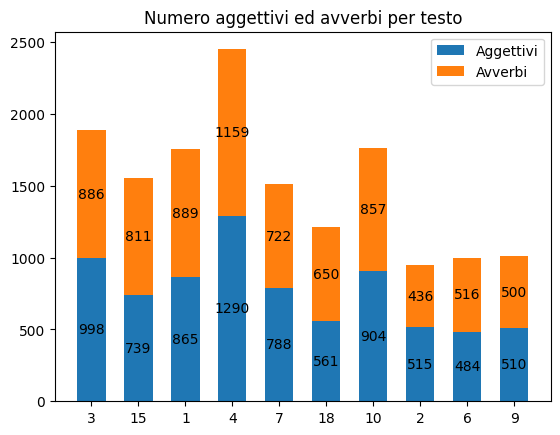

In [ ]:
testi = ('3', '15', '1', '4', '7','18','10','2','6','9')
pos_counting = {
    'Aggettivi': np.array([ 998,  739,  865, 1290 , 788,  561,  904,  515,  484,  510]),
    'Avverbi': np.array([ 886,  811,  889, 1159 , 722,  650,  857,  436,  516,  500]),
}
width = 0.6


fig, ax = plt.subplots()
bottom = np.zeros(10)

for elemento, pos_counting in pos_counting.items():
    p = ax.bar(testi, pos_counting, width, label=elemento, bottom=bottom)
    bottom += pos_counting

    ax.bar_label(p, label_type='center')

ax.set_title('Numero aggettivi ed avverbi per testo')
ax.legend()

plt.show()

3 annoyance 15 gratitude 1 amusement 4 approval 7 curiosity 18 love 10 disapproval 2 anger 6 confusion 9 disappointment

5 neg 5 pos

In [ ]:
array_verbi=np.array([annoyance_conteggio[0]["VERB"],gratitude_conteggio[0]["VERB"],amusement_conteggio[0]["VERB"],approval_conteggio[0]["VERB"],curiosity_conteggio[0]["VERB"],love_conteggio[0]["VERB"],disapproval_conteggio[0]["VERB"],anger_conteggio[0]["VERB"],confusion_conteggio[0]["VERB"],disappointment_conteggio[0]["VERB"]])

In [ ]:
print(array_verbi)

[3113 3502 2973 3854 2570 3036 2769 1868 1843 1500]


In [ ]:
array_nomi=np.array([annoyance_conteggio[0]["NOUN"],gratitude_conteggio[0]["NOUN"],amusement_conteggio[0]["NOUN"],approval_conteggio[0]["NOUN"],curiosity_conteggio[0]["NOUN"],love_conteggio[0]["NOUN"],disapproval_conteggio[0]["NOUN"],anger_conteggio[0]["NOUN"],confusion_conteggio[0]["NOUN"],disappointment_conteggio[0]["NOUN"]])

In [ ]:
print(array_nomi)

[3733 3887 4005 4176 2999 2994 3289 2200 1872 1640]


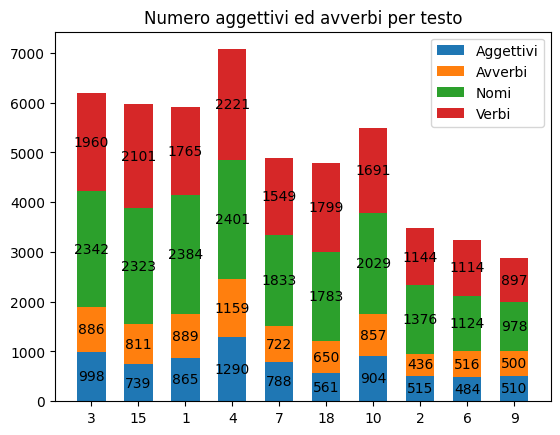

In [ ]:
testi = ('3', '15', '1', '4', '7','18','10','2','6','9')
pos_counting = {
    'Aggettivi': np.array([ 998,  739,  865, 1290 , 788,  561,  904,  515,  484,  510]),
    'Avverbi': np.array([ 886,  811,  889, 1159 , 722,  650,  857,  436,  516,  500]),
    'Nomi': np.array([ 2342, 2323, 2384, 2401, 1833, 1783, 2029, 1376, 1124,  978]),
    'Verbi': np.array([ 1960, 2101, 1765, 2221, 1549, 1799, 1691, 1144, 1114,  897]),
}
width = 0.6


fig, ax = plt.subplots()
bottom = np.zeros(10)

for elemento, pos_counting in pos_counting.items():
    p = ax.bar(testi, pos_counting, width, label=elemento, bottom=bottom)
    bottom += pos_counting

    ax.bar_label(p, label_type='center')

ax.set_title('Numero aggettivi ed avverbi per testo')
ax.legend()

plt.show()

3 annoyance 15 gratitude 1 amusement 4 approval 7 curiosity 18 love 10 disapproval 2 anger 6 confusion 9 disappointment

5 neg 5 pos